# Tiling: exploration and QC

This notebook checks the tiles written by `data_prep/tile.py` for the 259 slides in subset B.
It only reads files; nothing here changes the data.

**How to use:** run the Setup and Settings cells first, then any section. Run it in the `gbm-mgmt`
conda environment. The cells read `patches/index_B.csv`, each slide's `.h5` file and its `_qc.png`.

Findings and next steps for the full run are in the last section.


### Tiling config history

| Version | Grid and tile reads | Tissue mask |
|---|---|---|
| tiling-v1 | Custom grid in level-0 coordinates | TIAToolbox grayscale Otsu |
| tiling-v2 | TIAToolbox `SlidingWindowPatchExtractor` | TIAToolbox grayscale Otsu |
| tiling-v3 | TIAToolbox `SlidingWindowPatchExtractor` | Saturation channel, lower cut of a three-class Otsu |
| tiling-v4 | As v3, plus a quality filter that drops empty or featureless tiles | As v3 |
| tiling-v5 (current) | Same tiles as v4. Adds per-tile glass and blur scores to each `.h5`, config validation, and rerun checks (code version, `.h5` size, QC image) | As v3 |

## Setup

All imports for the notebook, including `tile.py` and `download.py` from the repo's `data_prep/` folder
(set by `REPO`). Run this first. Importing TIAToolbox takes several seconds because it loads PyTorch.

In [5]:
import hashlib
import io
import sys
from pathlib import Path
from tqdm.auto import tqdm
import cv2
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from tiatoolbox.wsicore.wsireader import WSIReader

# The repo's data_prep/ scripts, used by the "Before" cell.
REPO = Path("~/Bioinformatics/WSI/gbm-mgmt-wsi").expanduser()
sys.path.insert(0, str(REPO / "data_prep"))
import tile                                    # noqa: E402
from download import load_manifest, paths_for  # noqa: E402

### Settings

Used by the comparison cell (Tile scale and appearance).

- `ROOT`: the data folder that `download.py` and `tile.py` write to
- `SUBSET`: which `index_<SUBSET>.csv` to read
- `SEED`: picks the random slides and the random tiles; the same seed shows the same ones every run
- `SLIDES`: 10 random slides from `index_<SUBSET>.csv`, picked with `SEED`
- `GRID`: tiles per side of each tile grid (4 → 16 tiles)
- `SCALE_BAR_UM`: length of the scale bar drawn on each tile grid

The other sections set their own settings at the top of their cell. Their slide lists have their own names
(`CHECK_SLIDES`, `DROP_SLIDES`, `VIEW_SLIDES`) so they don't overwrite `SLIDES`, but the "Before" cell sets
`ROOT` and `GRID` again.

In [ ]:
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SUBSET = "B"
# seed for reproducibility of slides
SEED = 2026
index = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
# get 10 random slides from the index for visualization
SLIDES = index.sample(n=10, random_state=SEED).slide_id.tolist()
GRID = 4            # GRID x GRID "tiles per slide
SCALE_BAR_UM = 20

## Before the saturation mask (tiling-v2)

The tiling-v2 files were overwritten by the tiling-v3 run, so this cell rebuilds the tiles in memory instead
of reading them. It uses the current `tile.py` with `mask_method: otsu_gray`, which is the same mask, grid
and seeds as tiling-v2, so it reproduces the same 2,000 sampled tiles and the same 16 shown by the
comparison cell. Nothing is written. It needs the slide's `.svs` file under `ROOT/raw/` and imports
`tile.py` from the repo. `BEFORE_QC` is the copy of the tiling-v2 QC image saved before rerunning.

**Result:** the rebuild reports 8,617 tissue tiles for TCGA-12-0819, matching the tiling-v2 run, and the
blank beige tile (second row, first column) is back. It comes from the slide/coverslip edge, which the
grayscale mask outlined as tissue (the green line on the right of the QC image).

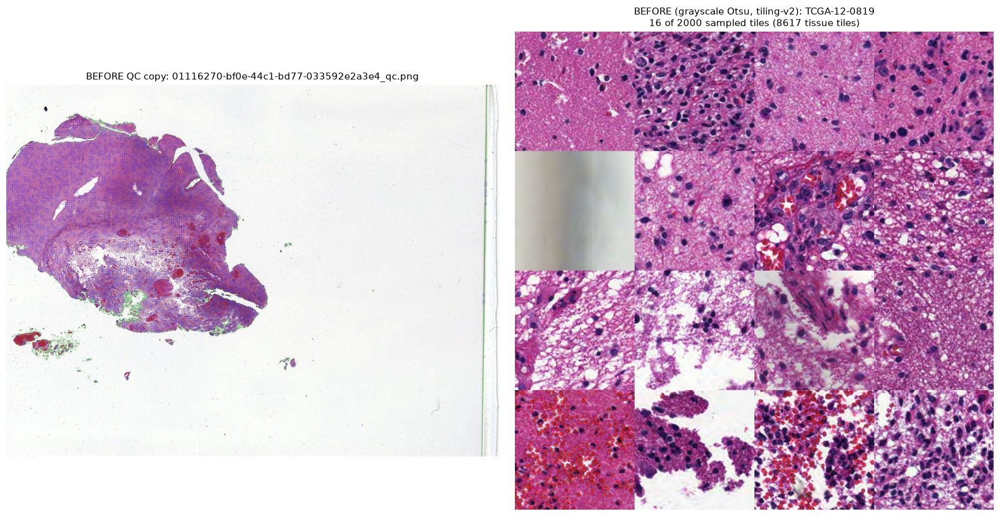

In [3]:
# BEFORE the saturation mask: rebuild the 16 random tiles the comparison cell showed under tiling-v2
# (grayscale Otsu), in memory without touching any files, next to the copied tiling-v2 QC image.
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SLIDE = "TCGA-12-0819-01Z-00-DX2"   # slide ID or file-name prefix
BEFORE_QC = Path("~/Desktop/qc_otsu/01116270-bf0e-44c1-bd77-033592e2a3e4_qc.png").expanduser()
GRID = 4
SEED = 0                            # same SEED as the comparison cell -> same 16 tiles

# tiling-v2 = current settings with the grayscale Otsu mask.
cfg = {**tile.load_config(REPO / "configs" / "tiling.yaml")[0], "mask_method": "otsu_gray"}
_, manifest = load_manifest(tile.DEFAULT_MANIFEST)
row = next(r for r in manifest["files"] if r["slide_id"] == SLIDE or r["file_name"].startswith(SLIDE))

wsi = WSIReader.open(paths_for(ROOT, row)[0])
_, _, _, extractor = tile.tissue_grid(wsi, cfg)
n_tissue = len(extractor.coordinate_list)

# Same sampling as tile.py's tile_slide, then the same 16-tile pick as the comparison cell.
seed = int.from_bytes(hashlib.sha256(f"{cfg['seed']}|{row['slide_id']}".encode()).digest()[:8], "big")
count = min(n_tissue, cfg["max_tiles_per_slide"])
chosen = np.sort(np.random.default_rng(seed).choice(n_tissue, size=count, replace=False))
shown = sorted(np.random.default_rng(SEED).choice(count, size=min(GRID * GRID, count), replace=False))
tiles = [extractor[int(chosen[i])][..., :3] for i in shown]

px = cfg["tile_px"]
grid = np.full((GRID * px, GRID * px, 3), 255, dtype=np.uint8)
for k, t in enumerate(tiles):
    r, c = divmod(k, GRID)
    grid[r * px:(r + 1) * px, c * px:(c + 1) * px] = t

fig, (ax_qc, ax_tiles) = plt.subplots(1, 2, figsize=(16, 8))
if BEFORE_QC.exists():
    ax_qc.imshow(Image.open(BEFORE_QC))
    ax_qc.set_title(f"BEFORE QC copy: {BEFORE_QC.name}", fontsize=11)
ax_qc.axis("off")
ax_tiles.imshow(grid)
ax_tiles.set_title(f"BEFORE (grayscale Otsu, tiling-v2): {row['patient_id']}\n"
                   f"16 of {count} sampled tiles ({n_tissue} tissue tiles)", fontsize=11)
ax_tiles.axis("off")
plt.tight_layout()
plt.show()

## Tile scale and appearance (current config)

For each slide in `SLIDES` (10 random slides from Settings): the QC overview (tissue outline in green,
sampled tiles in blue) next to 16 random tiles, with a 20 µm scale bar on the bottom-left tile.

**What to check**

- **Scale:** nuclei and red blood cells (about 7 µm) should be the same size relative to the bar on every
  slide, 40× and 20×, TCGA and CPTAC. That confirms the resampling to 0.5 µm/px.
- **Coverage:** the blue tiles should sit on tissue, not on glass, the slide edge, pen marks or bubbles.
- **Gaps:** tissue inside the green outline with no blue tiles is either beyond the 2000-tile cap or
  removed by the quality filter (see the dropped-tiles section).

**Results (tiling-v5, 10 random slides, `SEED = 2026`)**

Slides: C3N-02185, C3N-02256, C3N-02769, TCGA-06-0122 DX3, TCGA-06-0169 DX1, TCGA-12-0670 DX1,
TCGA-12-1599 DX2, TCGA-14-1794 DX1, TCGA-15-1446 DX2 (40×), TCGA-27-1830 DX3.

- Scale is consistent: nuclei are the same size relative to the bar on the 40× slide and the 20× slides,
  in both cohorts.
- Coverage: on all 10 slides the blue tiles sit on tissue, with none on glass, slide edges or pen marks.
- 9 of the 10 slides dropped no tiles; TCGA-12-1599 dropped 8.
- Stain differs by cohort: CPTAC tiles are darker and more purple, TCGA tiles pinker. Worth stain
  augmentation or normalization in training.
- Some tiles are mostly blood (TCGA-15-1446, TCGA-27-1830), and a few cross a dark fold or fiber
  (TCGA-15-1446, C3N-02769). These are real slide content, not mask errors.
- None of the 10 is one of the problem slides found by the checks below; a random sample of 10 misses them.

**Pilot results (tiling-v3, 6 pilot slides, compared with tiling-v2)**

- Scale is consistent across 40× and 20× slides and across both cohorts.
- TCGA-14-0817: tissue tiles went from 2,408 to 3,122; the pale band at the top and most of the pale
  top-left section are now tiled.
- TCGA-12-0819: the slide-edge strip is no longer outlined or tiled (8,617 → 8,557 tissue tiles).
- TCGA-19-2625 (all pale): fully captured (5,885 → 6,061); faint dust specks are outlined but not tiled.
- CPTAC slides: essentially unchanged (C3N-01192-21: 1,724 → 1,769; C3N-02786-23: 864 → 913).

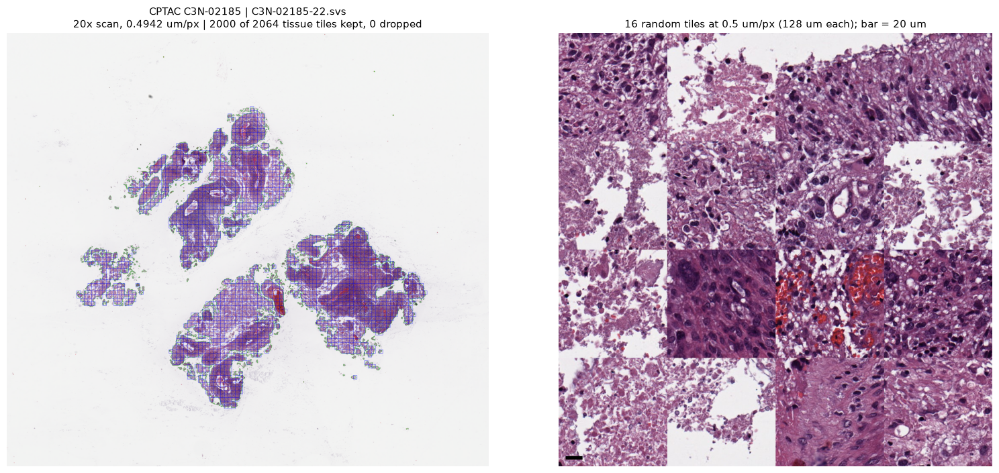

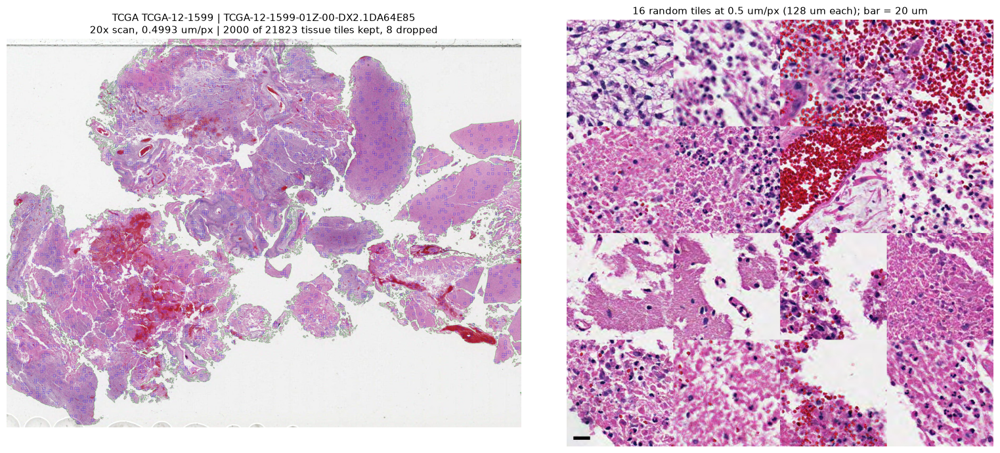

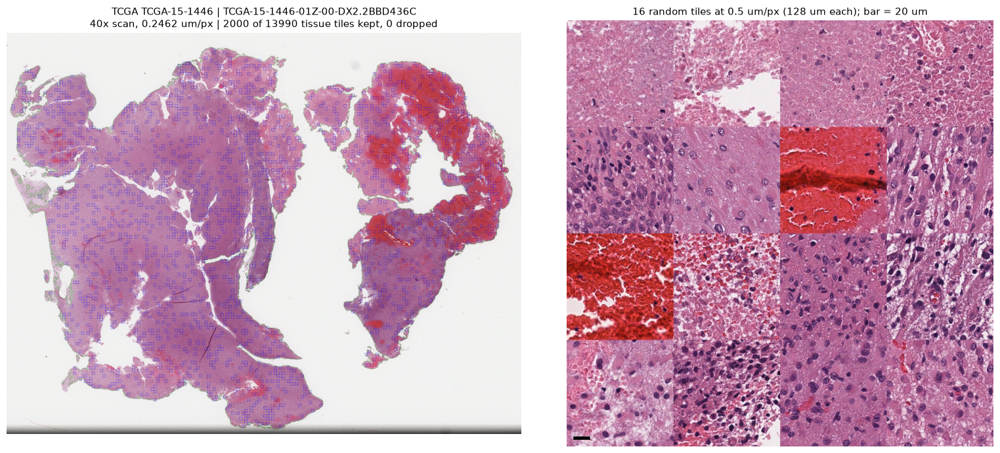

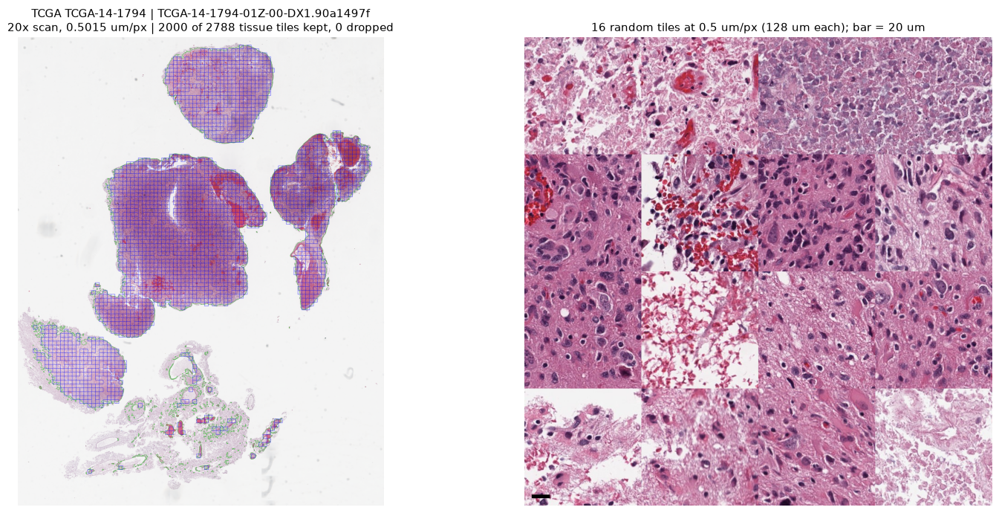

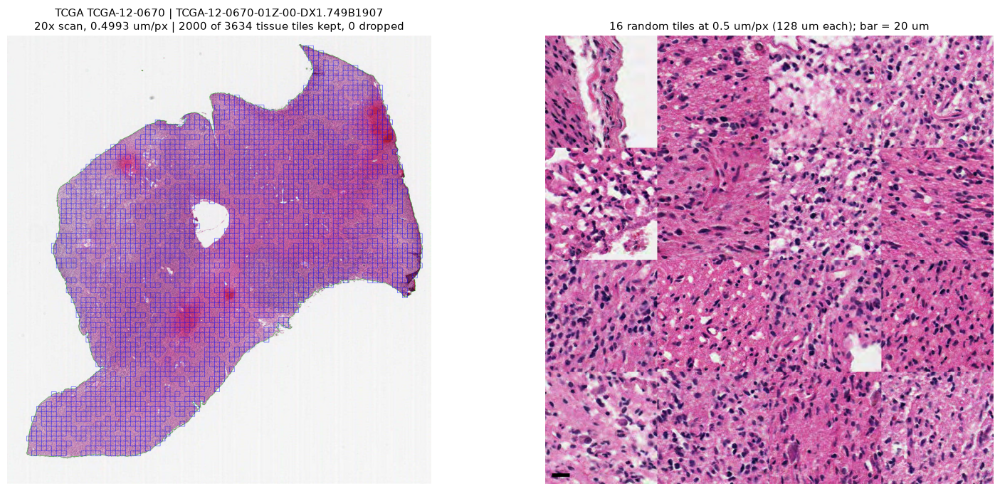

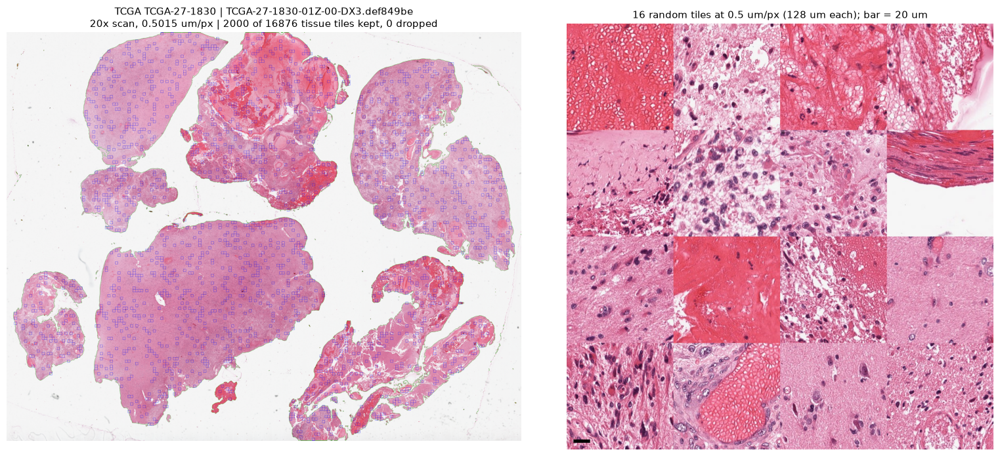

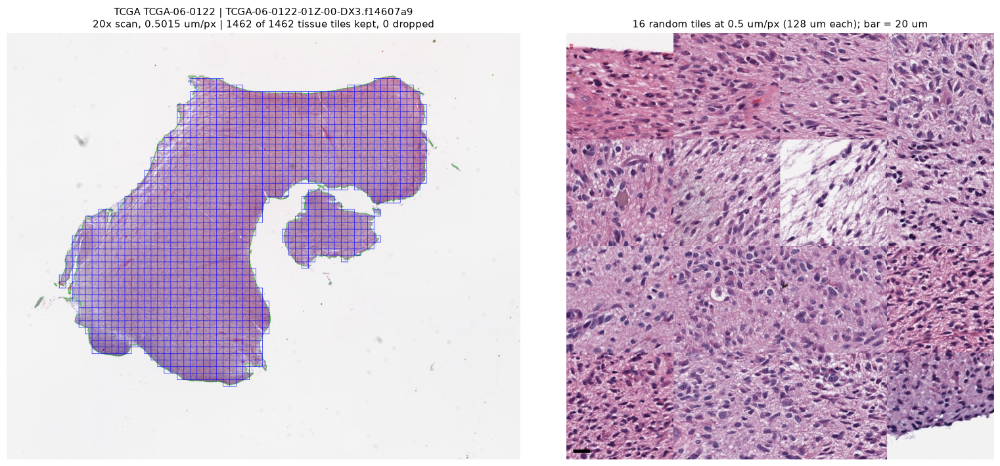

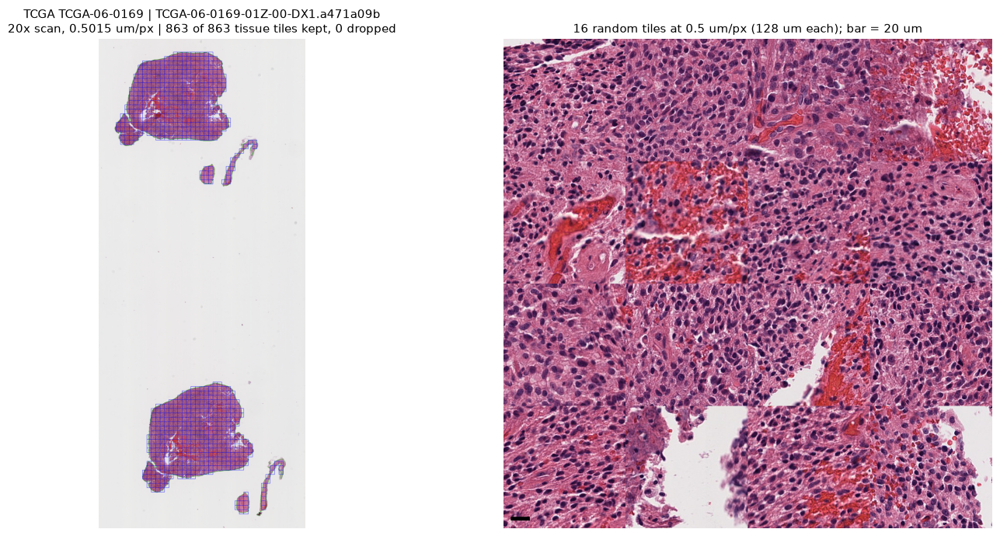

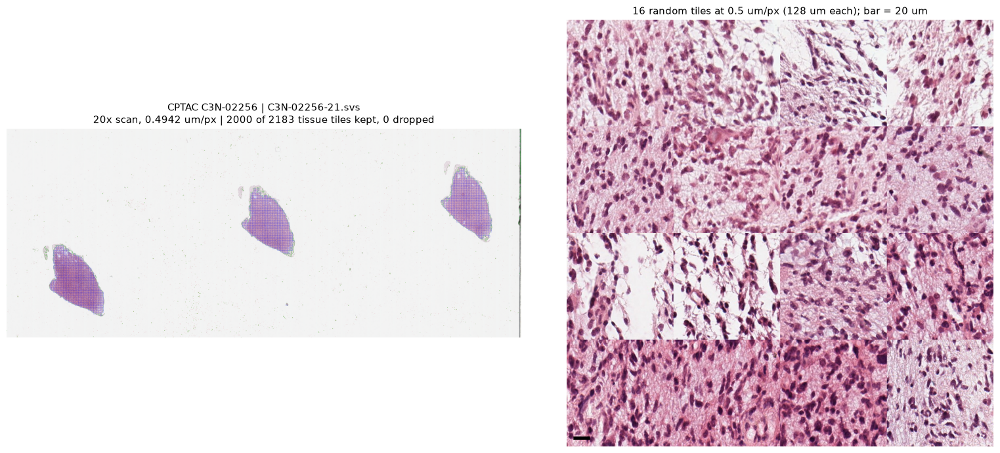

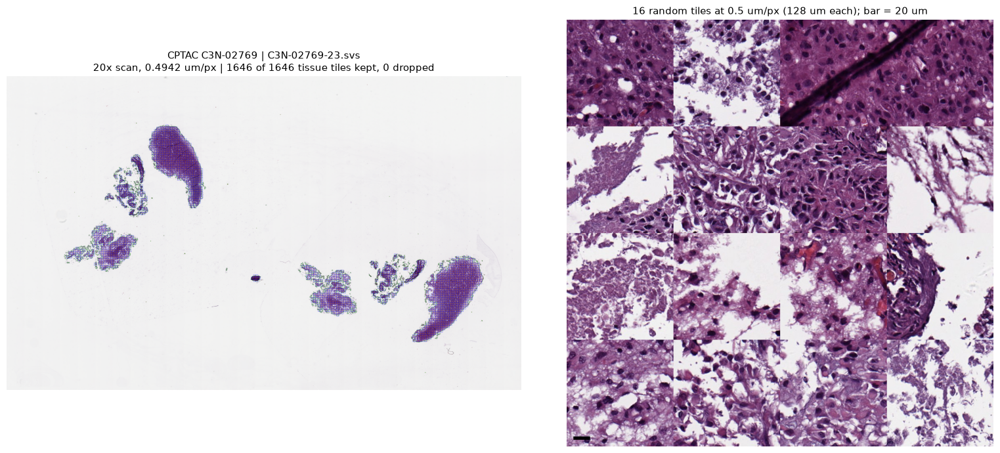

In [4]:
# Compare tiled slides: QC overview (tissue outline + sampled tiles) next to a grid of random tiles.
# Each tile grid has a 20 um scale bar, so nucleus size can be compared across slides and scanners.
index = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
rows = []
for key in SLIDES:
    match = index[(index.slide_id == key) | index.file_name.str.startswith(key)]
    if len(match) != 1:
        raise ValueError(f"{key}: {len(match)} matching slides in index_{SUBSET}.csv")
    rows.append(match.iloc[0])

for row in rows:
    h5_path = ROOT / row.h5
    qc = Image.open(h5_path.with_name(h5_path.stem + "_qc.png"))
    with h5py.File(h5_path) as h5:
        attrs = dict(h5.attrs)
        n = len(h5["tiles"])
        chosen = np.random.default_rng(SEED).choice(n, size=min(GRID * GRID, n), replace=False)
        tiles = [np.asarray(Image.open(io.BytesIO(h5["tiles"][i].tobytes()))) for i in sorted(chosen)]

    tile_px = int(attrs["tile_px"])
    grid = np.full((GRID * tile_px, GRID * tile_px, 3), 255, dtype=np.uint8)
    for k, img in enumerate(tiles):
        r, c = divmod(k, GRID)
        grid[r * tile_px:(r + 1) * tile_px, c * tile_px:(c + 1) * tile_px] = img
    bar_px = int(round(SCALE_BAR_UM / attrs["target_mpp"]))
    grid[-24:-16, 16:16 + bar_px] = 0   # black bar in the bottom-left tile

    scan = "40x" if attrs["source_mpp_x"] < 0.35 else "20x"
    fig, (ax_qc, ax_tiles) = plt.subplots(1, 2, figsize=(16, 7))
    ax_qc.imshow(qc)
    ax_qc.set_title(f"{row.source} {row.patient_id} | {row.file_name[:32]}\n"
                    f"{scan} scan, {attrs['source_mpp_x']:.4f} um/px | "
                    f"{attrs['n_sampled']} of {attrs['n_tissue_tiles']} tissue tiles kept, "
                    f"{attrs['n_dropped']} dropped", fontsize=11)
    ax_tiles.imshow(grid)
    ax_tiles.set_title(f"{len(tiles)} random tiles at {attrs['target_mpp']} um/px "
                       f"({attrs['tile_um']:.0f} um each); bar = {SCALE_BAR_UM} um", fontsize=11)
    for ax in (ax_qc, ax_tiles):
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Checking every tile

Scores every sampled tile on four measures, then shows, per slide, a contact sheet of all its tiles
(flagged tiles boxed in red, in grid order so neighbouring tiles form continuous tissue) and the 8 worst
tiles for each measure. A summary table of flag counts per slide comes last.

| Measure | Definition | Flag when | Catches |
|---|---|---|---|
| glass | fraction of uncolored glass (saturation < 8, value > 200) | > 0.5 | background, tissue edges |
| dark | fraction of very dark pixels (V < 60) | > 0.2 | folds, debris, ink |
| green | fraction of green pixels | > 0.02 | green marker ink |
| blur | variance of the Laplacian | < 50 | out-of-focus or featureless tiles |

Glass and blur come from `tile.tile_quality`, the same function `tile.py` uses for its quality filter
(it drops tiles with glass > 0.9 or blur < 20). Since tiling-v5, each `.h5` also stores these two scores per
tile. Flags here are looser on purpose: they mark tiles to look at, not tiles to drop.

**How to run it on subset B**

- **Whole subset:** `CHECK_SLIDES = None` and `SHOW_FIGURES = False` gives only the summary table
  (`flag_summary`, sorted by `any_flag`). It decodes every tile (up to 2,000 per slide × 259 slides), so
  expect it to take several minutes.
- **Then a few slides:** set `CHECK_SLIDES` to the slides with the most flags, e.g.
  `flag_summary.slide_id.head(3).tolist()`, and `SHOW_FIGURES = True`. Each slide's contact sheet adds
  several MB to the notebook, so keep the list short.

**Results (tiling-v5, subset B, all 259 slides)**

The top of the summary table:

| Slide | Kept tiles | Flagged | Flagged by | Mask threshold |
|---|---|---|---|---|
| TCGA-19-1389 DX1 | 911 | 908 | glass | 2 |
| TCGA-14-1829 DX5 | 2,000 | 861 | blur | 36 |
| TCGA-19-1387 DX1 | 2,000 | 725 | glass | 4 |
| TCGA-19-1390 DX1 | 935 | 698 | glass | 4 |
| C3N-02255 | 2,000 | 516 | glass | 6 |

- **Glass:** the heavily flagged slides all have a mask threshold of 8 or less (subset median 35). On very
  pale slides the lower cut of the three-class Otsu falls in background noise, so the mask covers glass.
  Tiles that are 50–90% glass pass the filter's 0.9 limit and are kept (see Whole-slide view).
- **Blur:** TCGA-14-1829 DX5 is soft across the whole slide (median blur 56). The patient has other slides
  (DX2, DX3, DX6).
- **Glass here vs in the `.h5`:** this cell measures the decoded JPEG; the `glass` stored in the `.h5` was
  measured before encoding and reads lower on pale background (TCGA-19-1387: 725 tiles over 0.5 here,
  209 stored).
- **Dark and green:** (fill in from `flag_summary[["dark_flagged", "green_flagged"]].sum()`)

**Pilot results (tiling-v3 tiles, about 10,700; flag counts with the original glass rule)**

| Slide | Flagged | What's really there |
|---|---|---|
| TCGA-12-0819 | 7 | One real artifact: a dark debris clump (dark 0.56, blur 16). The rest are tissue-edge tiles. |
| TCGA-14-0817 | 50 | Edge and fragmented tissue at 59–64% glass. One smeared tile (blur 164), not flagged. |
| TCGA-19-2625 | 1,805 | Mostly false alarms (see below); the worst is real: a blank background smudge (glass 1.00, blur 3). |
| TCGA-06-0878 | 40 | Tissue-edge tiles. |
| C3N-01192-21 | 55 | Tissue-edge tiles. |
| C3N-02786-23 | 38 | Tissue-edge tiles. |

Genuinely bad tiles are rare: about 3 of ~10,700 (under 0.1%).

**Fixed: the glass rule.** The original rule (saturation < 20) counted pale tissue as glass: TCGA-19-2625's
tissue sits at saturation 13–20, so 1,805 of its 2,000 tiles were flagged. Background on every pilot slide
sits at 0–3, so the rule is now saturation < 8. Glass flags with the new rule:

| Slide | Old rule | New rule | Highest glass (new rule) |
|---|---|---|---|
| C3N-01192-21 | 55 | 20 | 0.62 |
| C3N-02786-23 | 37 | 3 | 0.53 |
| TCGA-06-0878 | 39 | 5 | 0.54 |
| TCGA-12-0819 | 6 | 0 | 0.47 |
| TCGA-14-0817 | 50 | 14 | 0.59 |
| TCGA-19-2625 | 1,805 | 23 | 0.67 |

The most glass-like tiles under the new rule are all tissue edges with real cells.

**Quality filter check (simulated on the tiling-v3 tiles, became tiling-v4):** glass > 0.9 or blur < 20
drops exactly two tiles: the debris clump on TCGA-12-0819 (blur 16) and the blank smudge on TCGA-19-2625
(blur 3; its glass is only 0.45 because of a faint tint, so blur is what catches it). The next-lowest blur
on any slide is an out-of-focus tissue edge at 25, kept on purpose; real tissue otherwise starts around 83.
The tiling-v4 pilot run dropped exactly those two tiles.

In [6]:
# Check every tile of the tiled slides: per-tile quality measures, a flagged-tile summary,
# a contact sheet of ALL tiles per slide (flagged tiles boxed in red), and the worst tiles per measure.
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SUBSET = "B"
CHECK_SLIDES = None   # None = every slide in index_<SUBSET>.csv; or a list of slide IDs / file-name prefixes
THUMB_PX = 40         # size of each tile in the contact sheet
WORST_N = 8           # full-size examples shown per measure
SHOW_FIGURES = False  # True = contact sheet and worst tiles per slide (keep CHECK_SLIDES short)
FLAGS = {             # measure: (rule, limit) -- a tile is flagged when the rule holds
    "glass":  (">", 0.5),    # fraction of uncolored glass (saturation < 8, value > 200)
    "dark":   (">", 0.2),    # fraction of very dark pixels (folds, debris, ink)
    "green":  (">", 0.02),   # fraction of green pixels (green marker ink)
    "blur":   ("<", 50.0),   # variance of the Laplacian; low = out of focus or featureless
}


def tile_measures(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    glass, blur = tile.tile_quality(img)   # same definitions as tile.py's quality filter
    return {"glass": glass,
            "dark": float((v < 60).mean()),
            "green": float(((h >= 35) & (h <= 85) & (s > 60)).mean()),
            "blur": blur}


def flagged(row):
    return [m for m, (rule, limit) in FLAGS.items()
            if (row[m] > limit if rule == ">" else row[m] < limit)]


checked = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
if CHECK_SLIDES is not None:
    checked = checked[checked.slide_id.isin(CHECK_SLIDES)
                      | checked.file_name.str.startswith(tuple(CHECK_SLIDES))]
    if checked.empty:
        raise ValueError(f"no slides match {CHECK_SLIDES}")

summary = []
for slide in tqdm(list(checked.itertuples()), desc="slides"):
    with h5py.File(ROOT / slide.h5) as h5:
        tiles = [np.asarray(Image.open(io.BytesIO(t.tobytes()))) for t in h5["tiles"][:]]
    stats = pd.DataFrame([tile_measures(t) for t in tiles])
    stats["flagged_by"] = stats.apply(flagged, axis=1)
    bad = stats["flagged_by"].str.len() > 0
    summary.append({"slide_id": slide.slide_id, "patient": slide.patient_id,
                    "file": slide.file_name[:23], "tiles": len(tiles), "dropped": slide.n_dropped,
                    **{f"{m}_flagged": int(stats["flagged_by"].apply(lambda f: m in f).sum()) for m in FLAGS},
                    "any_flag": int(bad.sum()), "median_blur": round(stats.blur.median())})

    if not SHOW_FIGURES:
        continue

    # Contact sheet of every tile, flagged ones outlined in red.
    cols = int(np.ceil(np.sqrt(len(tiles) * 1.6)))
    rows = int(np.ceil(len(tiles) / cols))
    sheet = np.full((rows * THUMB_PX, cols * THUMB_PX, 3), 255, np.uint8)
    for k, img in enumerate(tiles):
        r, c = divmod(k, cols)
        small = cv2.resize(img, (THUMB_PX, THUMB_PX), interpolation=cv2.INTER_AREA)
        if bad[k]:
            cv2.rectangle(small, (0, 0), (THUMB_PX - 1, THUMB_PX - 1), (255, 0, 0), 2)
        sheet[r * THUMB_PX:(r + 1) * THUMB_PX, c * THUMB_PX:(c + 1) * THUMB_PX] = small
    plt.figure(figsize=(20, 20 * rows / cols))
    plt.imshow(sheet)
    plt.title(f"{slide.source} {slide.patient_id} {slide.file_name[:23]}: all {len(tiles)} tiles, "
              f"{int(bad.sum())} flagged (red)", fontsize=13)
    plt.axis("off")
    plt.show()

    # The worst tiles for each measure, full size, with their values.
    fig, axes = plt.subplots(len(FLAGS), WORST_N, figsize=(2.2 * WORST_N, 2.5 * len(FLAGS)), squeeze=False)
    for ax_row, (m, (rule, limit)) in zip(axes, FLAGS.items()):
        order = stats[m].sort_values(ascending=(rule == "<")).index[:WORST_N]
        for ax, k in zip(ax_row, order):
            ax.imshow(tiles[k])
            ax.set_title(f"{m} {stats.at[k, m]:.2f}" + (" *" if m in stats.at[k, "flagged_by"] else ""),
                         fontsize=9, color="red" if m in stats.at[k, "flagged_by"] else "black")
            ax.axis("off")
    fig.suptitle(f"{slide.patient_id}: worst {WORST_N} tiles per measure (* = past the flag limit)", fontsize=12)
    plt.tight_layout()
    plt.show()

flag_summary = pd.DataFrame(summary).sort_values("any_flag", ascending=False)
display(flag_summary)

slides:   0%|          | 0/259 [00:00<?, ?it/s]

,slide_id,patient,file,tiles,dropped,glass_flagged,dark_flagged,green_flagged,blur_flagged,any_flag,median_blur
220,18ed4f5f-5f1c-4f87-a79c-e8d2b6f167b0,TCGA-19-1389,TCGA-19-1389-01Z-00-DX1,911,1,908,0,0,11,908,99
214,b7f5df0f-caa4-45a2-9636-badcd1c89316,TCGA-14-1829,TCGA-14-1829-01Z-00-DX5,2000,859,0,0,0,861,861,56
219,89512c3f-ecdc-4594-bc27-3fa040401428,TCGA-19-1387,TCGA-19-1387-01Z-00-DX1,2000,460,725,0,0,2,725,1716
221,0243c8bf-709e-45ce-9c95-5c092364a963,TCGA-19-1390,TCGA-19-1390-01Z-00-DX1,935,410,698,0,0,6,698,505
70,C3N-02255-22,C3N-02255,C3N-02255-22.svs,2000,0,516,0,0,0,516,262
...,...,...,...,...,...,...,...,...,...,...,...
183,48297373-855b-4d48-abc9-4ee39655e194,TCGA-12-3651,TCGA-12-3651-01Z-00-DX3,2000,0,0,0,0,0,0,940
85,C3N-03182-21,C3N-03182,C3N-03182-21.svs,1028,0,0,0,0,0,0,972
194,f6e75081-256c-489e-a050-f9574b6ce4d3,TCGA-14-0817,TCGA-14-0817-01Z-00-DX3,2000,1,0,0,0,0,0,1774
68,C3N-02186-22,C3N-02186,C3N-02186-22.svs,2000,0,0,0,0,0,0,779


## Dropped tiles

**How `tile.py` samples:** it visits a slide's tissue tiles in a random order (fixed per slide by `seed` and
the slide ID). Each visited tile is checked against the quality filter (glass > 0.9 or blur < 20); a tile that
fails is dropped and the next tile in the order is checked. Sampling stops when 2,000 tiles are kept or the
tissue tiles run out, so `n_examined = n_sampled + n_dropped`. On capped slides, tiles past the stopping
point are never checked.

This cell lists every slide that dropped tiles, sorted by the share of examined tiles dropped, then shows a
random sample of `MAX_SHOWN` dropped tiles for the `TOP_N` worst slides (or for `DROP_SLIDES`). Dropped tiles
are not stored in the `.h5` files, only their coordinates (`dropped_coords`), so they are re-read from the
`.svs`.

**Results (tiling-v5, subset B):** 63 of 259 slides dropped tiles, 12,036 in total, 11,822 of them TCGA.
The dropped tiles are of three kinds:

| Kind | Slides | Scores | Verdict |
|---|---|---|---|
| Glass, dust and bubbles | TCGA-19-1791, 19-1390, 19-1387 (mask threshold 3–4) | glass 0.90–0.99 | Correct: the mask covered glass and the filter removed it |
| Flat, featureless color | TCGA-14-1827 DX2, 27-1835 DX2 | blur 1–5 | Correct; some show a straight scanner seam |
| Out-of-focus tissue, nuclei still visible | TCGA-12-0821 DX3, 14-1829 DX5, 27-1836 DX4 | blur about 3–19 | Real tissue, dropped by the blur rule |

The last two kinds overlap at blur 3–5, so no lower `min_blur` separates them cleanly.

**Proposed: keep `min_blur` at 20.** On TCGA-12-0821 the dropped tiles come from one out-of-focus region and
the slide still reaches 2,000 tiles. The heavily blurred slides are all TCGA and cluster by tissue source
site, while CPTAC (the test cohort) is sharp, so keeping blurred tiles risks a site shortcut. Robustness to
blur can come from blur augmentation in training instead.

63 of 259 slides dropped tiles; 12036 dropped in total


,slide_id,patient_id,file_name,mask_threshold,n_tissue_tiles,n_examined,n_dropped,drop_pct,n_sampled
224,1a9b1016-d6e7-4276-94d8-9289cbc8ca30,TCGA-19-1791,TCGA-19-1791-01Z-00-DX1,3.0,5205,5205,4068,78.2,1137
163,a12ed831-9ee6-48cb-9f33-af55441ccb06,TCGA-12-0821,TCGA-12-0821-01Z-00-DX3,46.0,12865,4123,2123,51.5,2000
208,dbbba1b5-c2c3-4294-8488-5e5fe4babc72,TCGA-14-1827,TCGA-14-1827-01Z-00-DX2,42.0,12472,2889,889,30.8,2000
221,0243c8bf-709e-45ce-9c95-5c092364a963,TCGA-19-1390,TCGA-19-1390-01Z-00-DX1,4.0,1345,1345,410,30.5,935
240,0006ae80-5774-4199-bbd0-3c120ed547e6,TCGA-27-1835,TCGA-27-1835-01Z-00-DX2,34.0,14349,2867,867,30.2,2000
...,...,...,...,...,...,...,...,...,...
170,e275e21b-da9e-46fb-a1b7-4bd33363f3a6,TCGA-12-1088,TCGA-12-1088-01Z-00-DX1,43.0,5397,2001,1,0.0,2000
210,15747aa7-bef8-4d18-baa9-a396661df3f6,TCGA-14-1829,TCGA-14-1829-01Z-00-DX3,29.0,9663,2001,1,0.0,2000
205,c82ea72a-a309-4542-8bd0-56fe3f805f55,TCGA-14-1795,TCGA-14-1795-01Z-00-DX3,34.0,15833,2001,1,0.0,2000
186,2f67e999-7308-42b8-b441-d818dc041ea4,TCGA-12-3652,TCGA-12-3652-01Z-00-DX1,39.0,15155,2001,1,0.0,2000


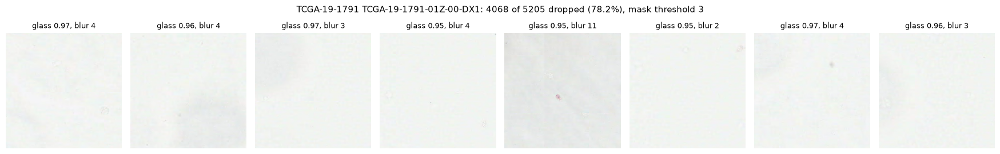

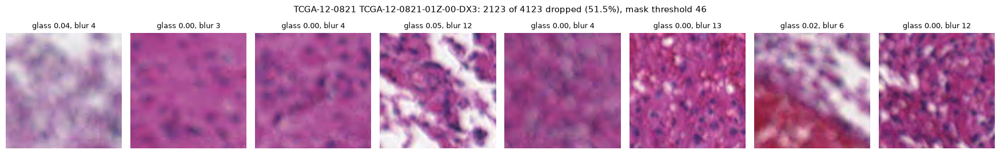

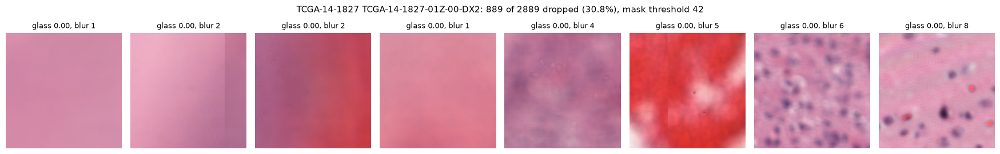

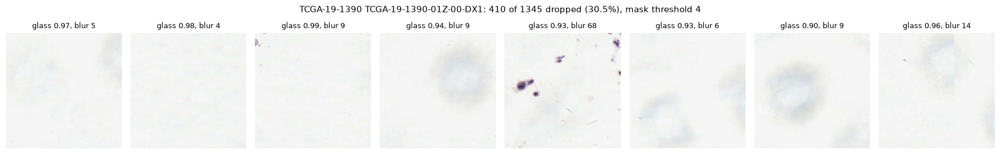

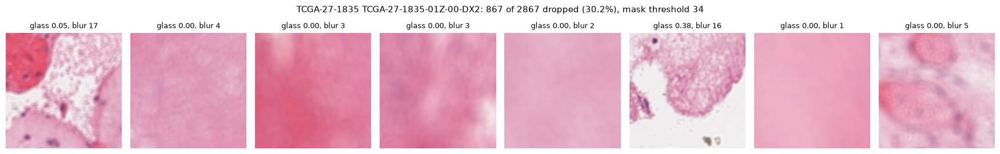

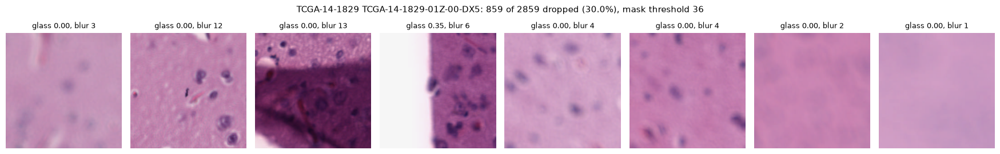

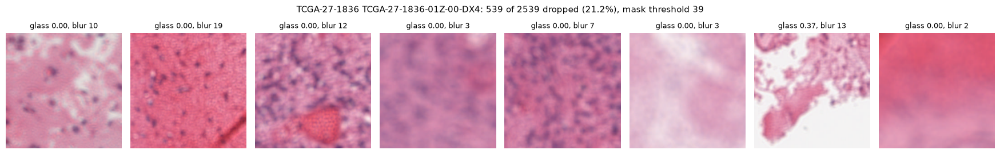

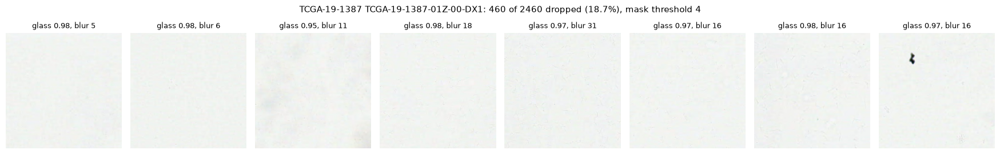

In [7]:
# Quality-filter results: per-slide drop summary, then a sample of the dropped tiles for the worst slides.
# Dropped tiles are not stored in the .h5 files (only their coordinates), so they are re-read from the slide.
ROOT = Path("~/Bioinformatics/WSI/data").expanduser()
SUBSET = "B"
DROP_SLIDES = None   # None = the TOP_N slides with the highest share dropped; or a list of slide IDs / prefixes
TOP_N = 8            # slides shown when DROP_SLIDES is None
MAX_SHOWN = 8        # dropped tiles shown per slide (random sample)

results = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
results["drop_pct"] = (100 * results.n_dropped / results.n_examined).round(1)
drops = (results[results.n_dropped > 0]
         .sort_values("drop_pct", ascending=False)
         [["slide_id", "patient_id", "file_name", "mask_threshold", "n_tissue_tiles",
           "n_examined", "n_dropped", "drop_pct", "n_sampled"]])
print(f"{len(drops)} of {len(results)} slides dropped tiles; {results.n_dropped.sum()} dropped in total")
display(drops.assign(file_name=drops.file_name.str[:23]))

if DROP_SLIDES is None:
    show = drops.head(TOP_N)
else:
    show = drops[drops.slide_id.isin(DROP_SLIDES) | drops.file_name.str.startswith(tuple(DROP_SLIDES))]
    if show.empty:
        raise ValueError(f"no slides with drops match {DROP_SLIDES}")

for slide in show.itertuples():
    row = results[results.slide_id == slide.slide_id].iloc[0]
    with h5py.File(ROOT / row.h5) as h5:
        attrs = dict(h5.attrs)
        dropped = h5["dropped_coords"][:]
    pick = np.random.default_rng(SEED).choice(len(dropped), size=min(MAX_SHOWN, len(dropped)), replace=False)
    wsi = WSIReader.open(paths_for(ROOT, {"source": row.source, "patient_id": row.patient_id,
                                          "slide_id": row.slide_id, "file_name": row.file_name})[0])
    px = int(attrs["tile_px"])
    fig, axes = plt.subplots(1, MAX_SHOWN, figsize=(2.2 * MAX_SHOWN, 2.8), squeeze=False)
    for ax in axes[0]:
        ax.axis("off")
    for ax, k in zip(axes[0], sorted(pick)):
        x, y = dropped[k]
        img = np.ascontiguousarray(wsi.read_rect((int(x), int(y)), (px, px), attrs["target_mpp"], "mpp",
                                                 coord_space="resolution")[..., :3])
        glass, blur = tile.tile_quality(img)
        ax.imshow(img)
        ax.set_title(f"glass {glass:.2f}, blur {blur:.0f}", fontsize=9)
    fig.suptitle(f"{row.patient_id} {row.file_name[:23]}: {slide.n_dropped} of {slide.n_examined} dropped "
                 f"({slide.drop_pct}%), mask threshold {slide.mask_threshold:.0f}", fontsize=11)
    plt.tight_layout()
    plt.show()

## Whole-slide view

For each slide in `VIEW_SLIDES`: the full slide at `THUMB_MPP` next to the same thumbnail with kept tiles
(blue) and dropped tiles (red). Only visited tiles are drawn, so on capped slides some tissue has no box.

**Results (tiling-v5)**

- **TCGA-19-1791 DX1** (mask threshold 3): the mask spread over the glass, but the filter dropped those tiles
  (red). The 1,137 kept tiles cover the three tissue sections and nothing else.
- **TCGA-19-1389 DX1** (mask threshold 2): the whole image is tiled, glass included, and only 1 tile was
  dropped. The tissue is almost unstained, barely darker than the glass, so most kept tiles show nothing
  useful. This slide should be excluded rather than fixed.

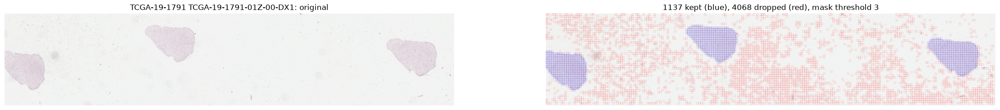

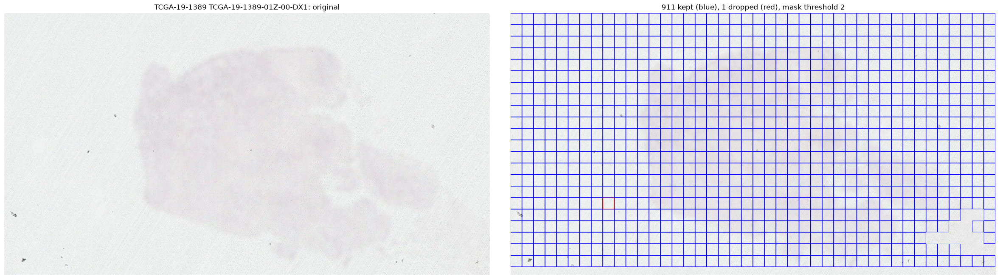

In [13]:
# Whole-slide view: the original thumbnail next to the same thumbnail with
# kept tiles (blue) and dropped tiles (red), one row per slide.
VIEW_SLIDES = ["TCGA-19-1791-01Z-00-DX1", "TCGA-19-1389-01Z-00-DX1"]   # slide IDs or file-name prefixes
THUMB_MPP = 4.0                     # thumbnail resolution in um/px (lower = sharper and bigger)

results = pd.read_csv(ROOT / "patches" / f"index_{SUBSET}.csv")
for key in VIEW_SLIDES:
    row = results[(results.slide_id == key) | results.file_name.str.startswith(key)].iloc[0]
    with h5py.File(ROOT / row.h5) as h5:
        attrs = dict(h5.attrs)
        kept, dropped = h5["coords"][:], h5["dropped_coords"][:]

    wsi = WSIReader.open(paths_for(ROOT, {"source": row.source, "patient_id": row.patient_id,
                                          "slide_id": row.slide_id, "file_name": row.file_name})[0])
    original = np.ascontiguousarray(wsi.slide_thumbnail(THUMB_MPP, "mpp")[..., :3])
    overlay = original.copy()
    scale = attrs["target_mpp"] / THUMB_MPP             # tile coords are at target_mpp
    size = int(round(attrs["tile_px"] * scale))
    for coords, color in ((kept, (0, 0, 255)), (dropped, (255, 0, 0))):
        for x, y in (coords * scale).round().astype(int):
            cv2.rectangle(overlay, (x, y), (x + size - 1, y + size - 1), color, 1)

    height, width = original.shape[:2]
    fig, (ax_orig, ax_tiles) = plt.subplots(1, 2, figsize=(24, 12 * height / width))
    ax_orig.imshow(original)
    ax_orig.set_title(f"{row.patient_id} {row.file_name[:23]}: original", fontsize=12)
    ax_tiles.imshow(overlay)
    ax_tiles.set_title(f"{len(kept)} kept (blue), {len(dropped)} dropped (red), "
                       f"mask threshold {row.mask_threshold:.0f}", fontsize=12)
    for ax in (ax_orig, ax_tiles):
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
TCGA-19-1389

## Findings and next steps (tiling-v5, subset B)

1. **Mask on very pale slides (tiling-v6).** Eight slides have a mask threshold of 8 or less: TCGA-19-1389,
   19-1791, 19-1387, 19-1390, 19-1787, 19-1789, C3N-02255 and C3N-01851. Proposed fix: never let the
   threshold go below 8, the same saturation cut the glass rule uses for "uncolored". Check it on
   TCGA-19-1390 and 19-1791 with `--slides` before the full rerun. On TCGA-19-1389 it may leave no tissue
   tiles at all, so `tile.py` needs to handle an empty slide.
2. **Exclude TCGA-19-1389 DX1** (almost unstained). Consider excluding **TCGA-14-1829 DX5** (out of focus
   throughout; the patient has other slides).
3. **Blur filter:** keep `min_blur` at 20; add blur augmentation in training if needed.
4. **Subset A:** Carlos tiles from the tiling-v6 commit.
5. **Training notes:** stain differs between TCGA and CPTAC; some slides have only about 100 kept tiles, others
   2,000; serial sections give near-duplicate tiles. Pool each patient's slides and weight by patient.